# El lazo de Gerchberg-Saxton sobre nueve trampas

**Pregunta:** ¿Qué hace cada mitad de una iteración de Gerchberg-Saxton a las trampas, y a qué converge el lazo?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** notebooks 01 y 02 del tema 01 y notebook 01 del tema 02
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Un método iterativo hace un holograma yendo y viniendo entre dos planos: en el plano de las trampas fija lo que se quiere, en el plano del SLM fija lo que el dispositivo puede hacer. Este notebook abre una iteración de Gerchberg-Saxton en sus dos mitades y ejecuta cada una a mano sobre el caso más pequeño del producto, nueve trampas iguales sobre un cuadrado. Verás que la mitad hacia adelante mide las trampas, que la restricción reemplaza sus amplitudes y conserva sus fases, y que la mitad hacia atrás envía el resultado al SLM, donde solo puede conservarse la fase. Luego comprobarás que la iteración del propio motor es exactamente esos pasos, ejecutarás treinta iteraciones y leerás a qué converge el lazo y a qué no.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m02_random_superposition, m04_gs

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def amp_spread(v):
    """Relative standard deviation of the trap amplitudes, in percent."""
    return 100.0 * np.std(np.abs(v)) / np.mean(np.abs(v))

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C01, nueve trampas separadas 3,98 um sobre el SLM de 256 por 256 píxeles, con la semilla del caso.

In [2]:
# case C01: nine equal traps on a 3 x 3 square, 8 bins apart; the target amplitude of trap m is sqrt(w_m)
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C01_square_grid"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seed = rec["seed"]
amp = np.sqrt(traps.weight)
print(f"{len(traps)} trampas, amplitudes objetivo {amp}")

9 trampas, amplitudes objetivo [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Método

Sea $V_m = \frac{1}{N}\sum_j A_j e^{i(\phi_j - \Delta_j^m)}$ el campo en la trampa $m$ para el holograma $\phi$, y $a_m = \sqrt{w_m}$ la amplitud objetivo. Una iteración de Gerchberg-Saxton es
$$\phi_j^{k} = \arg \sum_m a_m \frac{V_m^{k-1}}{|V_m^{k-1}|}\, e^{+i\Delta_j^m}$$
(Di Leonardo et al. 2007, Tabla 1, https://doi.org/10.1364/OE.15.001913). Se lee en tres movimientos. La mitad hacia adelante calcula $V_m$ a partir del holograma actual. La restricción conserva la fase de cada $V_m$ y fija su amplitud en $a_m$. La mitad hacia atrás suma las $M$ redes con esos coeficientes complejos para obtener un campo complejo en el SLM, y conserva solo su fase, porque el dispositivo modula solo la fase. El inicio es la superposición de fases aleatorias del tema anterior. Las celdas siguientes ejecutan los tres movimientos uno a uno, con los números de cada uno a la vista.

La primera celda construye el inicio y ejecuta la mitad hacia adelante sobre él: los nueve campos $V_m$ del holograma de superposición aleatoria. Imprime las nueve potencias de las trampas, los tres números del arreglo del tema 01 y la dispersión relativa de las amplitudes $|V_m|$, que es la cantidad que la restricción está por eliminar.

In [3]:
# the start: random-phase superposition (M02), then the first half step, the forward one
phi0 = m02_random_superposition.run(setup, target, budget=Budget(1), rng=Rng(seed)).phi
v0 = forward.point_trap_fields(phi0, setup, traps)
i0 = metrics.trap_intensities(v0)
print("potencias de las nueve trampas al inicio:", np.round(i0, 4))
print(f"e = {metrics.efficiency(i0):.4f}, u = {metrics.uniformity(i0):.4f}, sigma = {metrics.rel_std(i0):.2f} %")
print(f"dispersión de amplitudes: {amp_spread(v0):.2f} %")

potencias de las nueve trampas al inicio: [0.0648 0.1363 0.0827 0.0767 0.0738 0.0782 0.0667 0.0681 0.097 ]
e = 0.7442, u = 0.6444, sigma = 25.51 %
dispersión de amplitudes: 11.84 %


La restricción es aritmética. Para cada trampa el coeficiente es $c_m = a_m V_m/|V_m|$: la misma fase que el campo medido y la amplitud que se pidió. La celda imprime las amplitudes de los coeficientes, el mayor cambio de fase que hizo la restricción (debe ser cero hasta el redondeo) y la dispersión de amplitudes después, que es cero por construcción.

In [4]:
# the constraint: keep the phase of every trap field, replace its amplitude by the target amplitude
coeffs = amp * v0 / np.abs(v0)
print("amplitudes tras la restricción:", np.round(np.abs(coeffs), 4))
print(f"mayor cambio de fase de la restricción: {np.abs(np.angle(coeffs / v0)).max():.1e} rad")
print(f"dispersión de amplitudes: {amp_spread(coeffs):.2f} %")

amplitudes tras la restricción: [1. 1. 1. 1. 1. 1. 1. 1. 1.]
mayor cambio de fase de la restricción: 1.4e-17 rad
dispersión de amplitudes: 0.00 %


La mitad hacia atrás lleva los coeficientes al SLM. La adjunta de la mitad hacia adelante, `point_trap_backproject`, suma $\sum_m c_m e^{+i\Delta_j^m}$ sobre las trampas y da un campo complejo sobre los píxeles. Su amplitud no es constante, y el SLM no puede mostrar una amplitud, así que la celda conserva solo el ángulo, luego vuelve a ejecutar la mitad hacia adelante sobre ese holograma de solo fase e imprime los números del arreglo y la dispersión de amplitudes.

In [5]:
# the second half step: send the corrected trap fields back to the SLM and keep only the phase
field_slm = forward.point_trap_backproject(coeffs, setup, traps)
phi1 = np.angle(field_slm)
amplitude = np.abs(field_slm)
print("amplitud del campo del SLM retroproyectado:")
print(f"    min {amplitude.min():.3f}, mean {amplitude.mean():.3f}, max {amplitude.max():.3f}")
v1 = forward.point_trap_fields(phi1, setup, traps)
i1 = metrics.trap_intensities(v1)
print(f"e = {metrics.efficiency(i1):.4f}, u = {metrics.uniformity(i1):.4f}, sigma = {metrics.rel_std(i1):.2f} %")
print(f"dispersión de amplitudes: {amp_spread(v1):.2f} %")

amplitud del campo del SLM retroproyectado:
    min 0.056, mean 2.795, max 5.561
e = 0.7831, u = 0.6642, sigma = 21.81 %
dispersión de amplitudes: 10.22 %


Esa es la iteración completa. El método M04 del motor debe hacer exactamente esto cuando se le pide una iteración desde el mismo inicio con la forma de trampa puntual, y la celda compara los dos hologramas por la mayor diferencia de fase envuelta entre ellos.

In [6]:
# the same single iteration by the engine: M04 with a one-iteration budget, the same start and the point form
step = m04_gs.run(setup, target, budget=Budget(1), rng=Rng(seed), init=phi0, form="point")
wrapped = np.angle(np.exp(1j * (step.phi - phi1)))
print(f"mayor diferencia de fase, paso hecho a mano y M04: {np.abs(wrapped).max():.1e} rad")

mayor diferencia de fase, paso hecho a mano y M04: 0.0e+00 rad


Ahora el lazo. El motor tiene dos formas de la misma iteración: la forma de trampa puntual que este notebook usó a mano y la forma FFT, que lee y escribe la transformada con relleno de ceros en los bins de las trampas y es la predeterminada cuando las trampas están sobre bins. Son el mismo mapa lineal, de modo que deben dar el mismo holograma hasta el redondeo del caso: el caso guarda las posiciones de las trampas con 0,1 nm, así que quedan un poco fuera del centro de sus bins. La celda imprime ese desplazamiento y compara las dos formas tras 1, 8 y 30 iteraciones, por la mayor y la mediana de la diferencia de fase sobre los píxeles. La mayor diferencia resume mal, porque la fase de un píxel donde el campo retroproyectado es casi cero es muy sensible a un cambio diminuto.

In [7]:
# the point-trap form and the FFT form from the same start, after 1, 8 and 30 iterations
bin_m = geometry.focal_bin_m(setup)
offset = np.abs(traps.x_m / bin_m - np.rint(traps.x_m / bin_m)).max()
print(f"mayor distancia de una trampa al centro de su bin: {offset:.1e} bins")
forms = {}
for form in ("point", "fft"):
    forms[form] = {}
    for k in (1, 8, 30):
        forms[form][k] = m04_gs.run(setup, target, budget=Budget(k), rng=Rng(seed), init=phi0, form=form)
for k in (1, 8, 30):
    gap = np.angle(np.exp(1j * (forms["point"][k].phi - forms["fft"][k].phi)))
    print(f"mayor diferencia de fase entre las dos formas tras {k:2d} iteraciones:")
    print(f"    mayor {np.abs(gap).max():.1e}, mediana {np.median(np.abs(gap)):.1e} rad")
run_point = forms["point"][30]
last = run_point.history[-1]
e, u, sigma = last["efficiency"], last["uniformity"], last["rel_std"]
print(f"M04, 30 iteraciones: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

mayor distancia de una trampa al centro de su bin: 5.0e-05 bins
mayor diferencia de fase entre las dos formas tras  1 iteraciones:
    mayor 6.0e-03, mediana 2.8e-05 rad
mayor diferencia de fase entre las dos formas tras  8 iteraciones:
    mayor 4.0e-03, mediana 3.3e-05 rad
mayor diferencia de fase entre las dos formas tras 30 iteraciones:
    mayor 4.0e-03, mediana 3.4e-05 rad
M04, 30 iteraciones: e = 0.8193, u = 0.8794, sigma = 7.34 %


Todo método devuelve un historial con la eficiencia, la uniformidad y la dispersión relativa en cada iteración. La celda lo imprime en seis iteraciones y busca la iteración de mejor uniformidad.

In [8]:
# the history that every method returns: one entry per iteration
for k in (1, 2, 5, 10, 20, 30):
    h = run_point.history[k - 1]
    print(f"iteración {k:2d}: e = {h['efficiency']:.4f}, u = {h['uniformity']:.4f}, sigma = {h['rel_std']:.2f} %")
uniformity = [h["uniformity"] for h in run_point.history]
spread = [h["rel_std"] for h in run_point.history]
print(f"la uniformidad es máxima en la iteración {int(np.argmax(uniformity)) + 1}: u = {max(uniformity):.4f}")
print(f"la dispersión es mínima en la iteración {int(np.argmin(spread)) + 1}: sigma = {min(spread):.2f} %")

iteración  1: e = 0.7831, u = 0.6642, sigma = 21.81 %
iteración  2: e = 0.8021, u = 0.7701, sigma = 13.90 %
iteración  5: e = 0.8174, u = 0.9029, sigma = 5.75 %
iteración 10: e = 0.8189, u = 0.8910, sigma = 6.50 %
iteración 20: e = 0.8192, u = 0.8817, sigma = 7.19 %
iteración 30: e = 0.8193, u = 0.8794, sigma = 7.34 %
la uniformidad es máxima en la iteración 4: u = 0.9041
la dispersión es mínima en la iteración 5: sigma = 5.75 %


La primera figura sigue a las nueve trampas. Cada curva es la potencia de las trampas relativa a su promedio al inicio y tras 1, 5 y 30 iteraciones.

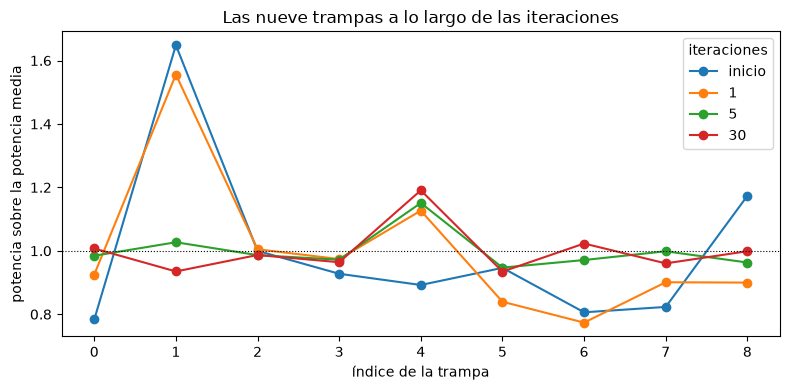

In [9]:
# the power of each of the nine traps at the start and after 1, 5 and 30 iterations
run_one = forms["point"][1]
run_five = m04_gs.run(setup, target, budget=Budget(5), rng=Rng(seed), init=phi0, form="point")
fig, ax = plt.subplots(figsize=(8, 4))
for label, res in (("inicio", None), ("1", run_one), ("5", run_five), ("30", run_point)):
    i = i0 if res is None else metrics.trap_intensities(res.fields)
    ax.plot(np.arange(9), i / i.mean(), "o-", label=label)
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("índice de la trampa")
ax.set_ylabel("potencia sobre la potencia media")
ax.set_title("Las nueve trampas a lo largo de las iteraciones")
ax.legend(title="iteraciones")
fig.tight_layout()
plt.show()

Al inicio dos trampas están lejos del resto, la trampa 1 en cerca de 1,65 del promedio y la trampa 8 en cerca de 1,2, y la trampa 6 está en 0,8. Tras una iteración la trampa 1 sigue en cerca de 1,55 y las demás se han movido poco: una iteración corrige la fase, no las potencias. Tras cinco iteraciones las nueve trampas quedan entre cerca de 0,93 y 1,15 del promedio. La iteración treinta no es mejor: la curva es algo menos plana que en la iteración cinco, y la trampa 4 queda cerca de 1,2. La figura no dice por qué; la siguiente sí.

La segunda figura grafica la eficiencia, la uniformidad y la dispersión relativa contra la iteración durante las treinta iteraciones.

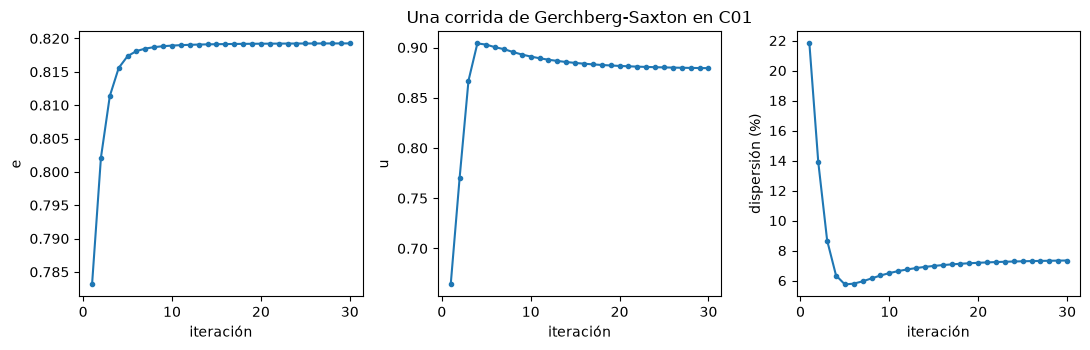

In [10]:
# efficiency, uniformity and relative spread against the iteration
steps = np.arange(1, 31)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, key, label in zip(axes, ("efficiency", "uniformity", "rel_std"), ("e", "u", "dispersión (%)")):
    ax.plot(steps, [h[key] for h in run_point.history], "o-", ms=3)
    ax.set_xlabel("iteración")
    ax.set_ylabel(label)
axes[1].set_title("Una corrida de Gerchberg-Saxton en C01")
fig.tight_layout()
plt.show()

La eficiencia sube de 0,7831 a 0,8193 y se aplana hacia la iteración 10: el lazo converge en el sentido de que el holograma deja de cambiar la luz que llega a las trampas. La uniformidad no: llega a su máximo de 0,9041 en la iteración 4, baja a 0,8794 en la iteración 30, y la dispersión pasa por un mínimo de 5,75 por ciento en la iteración 5 y sube a 7,34 por ciento. Esta es la limitación permanente de Gerchberg-Saxton simple, que no tiene ningún mecanismo que cuide que las trampas sean iguales después de aplicar la restricción: la restricción fija amplitudes iguales en cada iteración, pero la proyección de solo fase deshace una parte, y el lazo se asienta en un punto fijo de las dos operaciones que no es el arreglo igual. La figura muestra el efecto pero no su causa en una trampa cualquiera, y otro inicio daría otra curva.

## Resultados

**Respuesta:** La mitad hacia adelante mide el campo de cada trampa: al inicio las nueve potencias difieren con una dispersión de 25,51 por ciento y las amplitudes en 11,84 por ciento. La restricción conserva sus fases y fija las nueve amplitudes en 1, de modo que la dispersión de amplitudes es 0,00 por ciento. La mitad hacia atrás envía los coeficientes al SLM y conserva solo la fase de un campo cuya amplitud va de 0,056 a 5,561; las trampas quedan entonces con una dispersión de 10,22 por ciento en amplitud, de modo que el paso de solo fase devuelve parte del error que la restricción quitó. Una iteración así, hecha a mano, es idéntica a una iteración de M04 (diferencia de 0,0e+00 rad), y las dos formas del motor coinciden con una diferencia de fase mediana de 3,4e-05 rad tras 30 iteraciones. En 30 iteraciones la eficiencia se asienta en 0,8193 pero la uniformidad llega a 0,9041 en la iteración 4 y termina en 0,8794: Gerchberg-Saxton converge a un holograma eficiente, no uniforme.

## Resumen

Una iteración es una transformada hacia adelante, una restricción de amplitud en las trampas y una proyección de solo fase en el SLM. La restricción es exacta; la proyección es donde vuelve el error, porque un campo de solo fase no puede llevar las amplitudes que la restricción pidió. El punto fijo del lazo es eficiente pero no uniforme para este arreglo. Las variantes ponderadas del notebook siguiente cambian el coeficiente del paso de restricción para que a las trampas que salieron demasiado tenues se les pida más.

## Referencias

- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.